<a href="https://colab.research.google.com/github/moiz-shahid/Deep-Learning-Tutorials/blob/main/Tutorial-13-Denoising-Autoencoders/DL_Tutorial_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import copy
import os

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1+cu130
Device: cuda


In [2]:
transform = transforms.ToTensor()

full_train_dataset = datasets.MNIST(
    root="/content/mnist_data",
    train=True,
    transform=transform,
    download=True
)

test_dataset = datasets.MNIST(
    root="/content/mnist_data",
    train=False,
    transform=transform,
    download=True
)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [54000, 6000],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 494kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.56MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.68MB/s]

Training images: 54000
Validation images: 6000
Test images: 10000


In [3]:
NOISE_FACTOR = 0.5

def add_noise(images, noise_factor=0.5):

    noisy_images = images + (
        noise_factor * torch.randn_like(images)
    )

    noisy_images = torch.clamp(
        noisy_images,
        min=0.0,
        max=1.0
    )

    return noisy_images

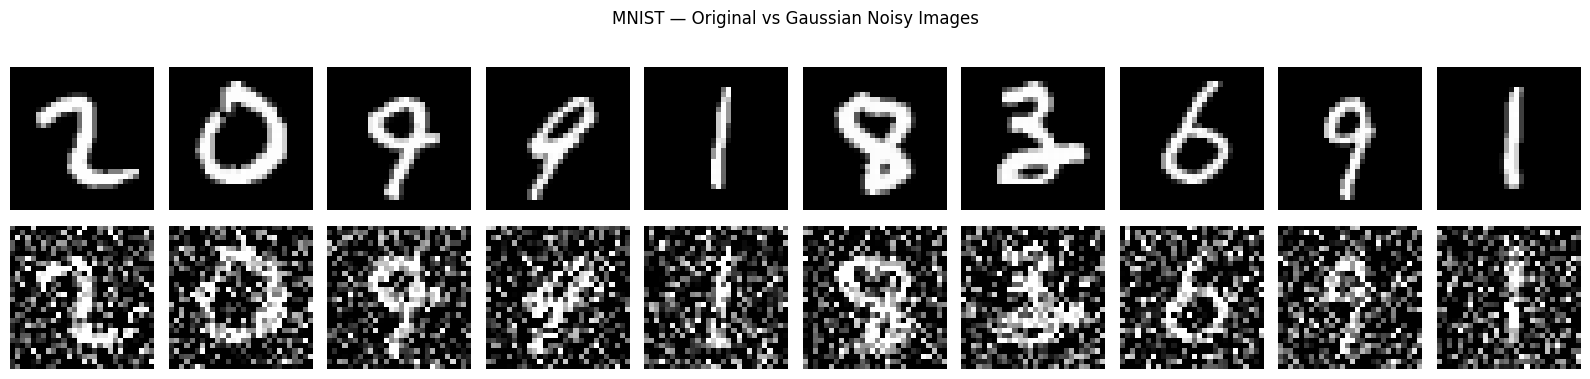

In [4]:
images, labels = next(iter(train_loader))

noisy_images = add_noise(
    images,
    noise_factor=NOISE_FACTOR
)

fig, axes = plt.subplots(2, 10, figsize=(16, 4))

for i in range(10):

    axes[0, i].imshow(
        images[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].imshow(
        noisy_images[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original", fontsize=11)
axes[1, 0].set_ylabel("Noisy", fontsize=11)

plt.suptitle("MNIST — Original vs Gaussian Noisy Images")
plt.tight_layout()
plt.show()

In [5]:
class DenoisingAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(

            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2)
        )

        # Decoder
        self.decoder = nn.Sequential(

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Upsample(scale_factor=2, mode="nearest"),

            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Upsample(scale_factor=2, mode="nearest"),

            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):

        encoded = self.encoder(x)
        decoded = self.decoder(encoded)

        return decoded


model = DenoisingAutoencoder().to(device)

print(model)

DenoisingAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Upsample(scale_factor=2.0, mode='nearest')
    (3): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): Upsample(scale_factor=2.0, mode='nearest')
    (6): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): Sigmoid()
  )
)


In [6]:
dummy_input = torch.rand(
    1, 1, 28, 28
).to(device)

model.eval()

with torch.no_grad():

    encoded = model.encoder(dummy_input)
    output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Latent shape:", encoded.shape)
print("Output shape:", output.shape)

total_params = sum(
    p.numel() for p in model.parameters()
)

print("Parameters:", f"{total_params:,}")

Input shape: torch.Size([1, 1, 28, 28])
Latent shape: torch.Size([1, 64, 7, 7])
Output shape: torch.Size([1, 1, 28, 28])
Parameters: 74,497


In [7]:
def evaluate_denoising(
    model,
    data_loader,
    noise_factor=0.5,
    seed=1234
):
    model.eval()

    criterion = nn.BCELoss(reduction="sum")
    mse_criterion = nn.MSELoss(reduction="sum")

    total_bce = 0
    total_mse = 0
    total_pixels = 0

    # Fixed noise for reproducible evaluation
    generator = torch.Generator().manual_seed(seed)

    with torch.no_grad():

        for clean, _ in data_loader:

            noise = torch.randn(
                clean.shape,
                generator=generator
            )

            noisy = torch.clamp(
                clean + noise_factor * noise,
                0, 1
            ).to(device)

            clean = clean.to(device)

            reconstructed = model(noisy)

            total_bce += criterion(
                reconstructed, clean
            ).item()

            total_mse += mse_criterion(
                reconstructed, clean
            ).item()

            total_pixels += clean.numel()

    return {
        "BCE": total_bce / total_pixels,
        "MSE": total_mse / total_pixels
    }


def train_denoising_autoencoder(
    model,
    train_loader,
    val_loader,
    epochs=10,
    lr=0.001,
    noise_factor=0.5
):

    criterion = nn.BCELoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_weights = None
    best_epoch = 0

    for epoch in range(epochs):

        model.train()
        running_loss = 0

        for clean, _ in train_loader:

            clean = clean.to(device)

            noisy = add_noise(
                clean,
                noise_factor
            )

            optimizer.zero_grad()

            reconstructed = model(noisy)

            # Target is the clean image
            loss = criterion(
                reconstructed,
                clean
            )

            loss.backward()
            optimizer.step()

            running_loss += (
                loss.item() * clean.size(0)
            )

        train_loss = (
            running_loss / len(train_loader.dataset)
        )

        val_metrics = evaluate_denoising(
            model,
            val_loader,
            noise_factor=noise_factor,
            seed=1234
        )

        val_loss = val_metrics["BCE"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_weights = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.5f} | "
            f"Val Loss: {val_loss:.5f}"
        )

    model.load_state_dict(best_weights)

    print("\nBest Epoch:", best_epoch)
    print("Best Validation Loss:", round(best_val_loss, 5))

    return model, history

In [8]:
torch.manual_seed(42)

model = DenoisingAutoencoder().to(device)

model, history = train_denoising_autoencoder(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    noise_factor=NOISE_FACTOR
)

Epoch 01/10 | Train Loss: 0.16055 | Val Loss: 0.11370
Epoch 02/10 | Train Loss: 0.10931 | Val Loss: 0.10607
Epoch 03/10 | Train Loss: 0.10459 | Val Loss: 0.10283
Epoch 04/10 | Train Loss: 0.10194 | Val Loss: 0.10096
Epoch 05/10 | Train Loss: 0.10036 | Val Loss: 0.09992
Epoch 06/10 | Train Loss: 0.09913 | Val Loss: 0.09892
Epoch 07/10 | Train Loss: 0.09837 | Val Loss: 0.09847
Epoch 08/10 | Train Loss: 0.09771 | Val Loss: 0.09726
Epoch 09/10 | Train Loss: 0.09712 | Val Loss: 0.09708
Epoch 10/10 | Train Loss: 0.09664 | Val Loss: 0.09695

Best Epoch: 10
Best Validation Loss: 0.09695


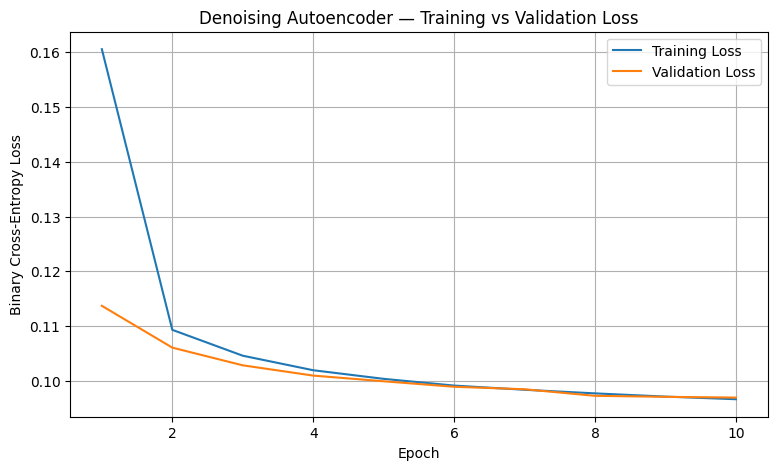

In [9]:
epochs_range = range(
    1, len(history["train_loss"]) + 1
)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

plt.title(
    "Denoising Autoencoder — Training vs Validation Loss"
)

plt.legend()
plt.grid(True)
plt.show()

In [10]:
test_metrics = evaluate_denoising(
    model,
    test_loader,
    noise_factor=NOISE_FACTOR,
    seed=5678
)

test_bce = test_metrics["BCE"]
test_mse = test_metrics["MSE"]

print("FINAL TEST RESULTS")
print("-" * 40)

print(f"Test BCE: {test_bce:.6f}")
print(f"Test MSE: {test_mse:.6f}")

FINAL TEST RESULTS
----------------------------------------
Test BCE: 0.095913
Test MSE: 0.011030


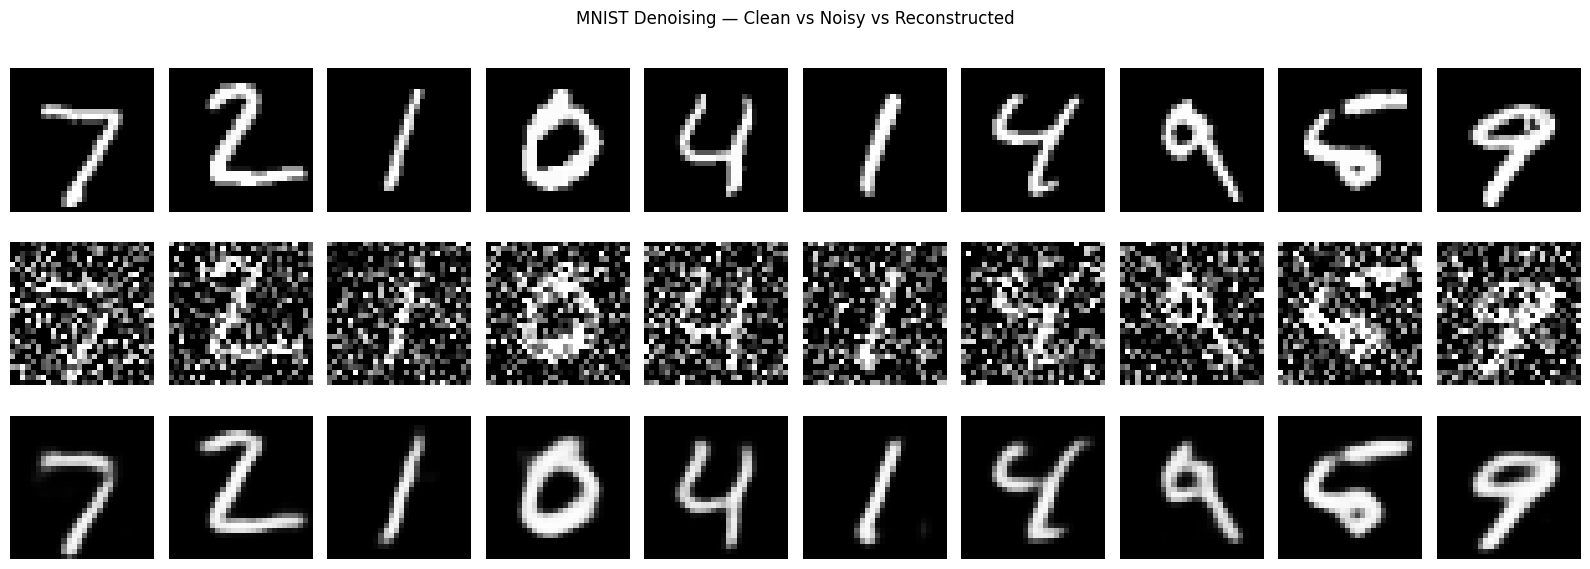

In [11]:
model.eval()

clean_images, labels = next(iter(test_loader))

clean_images = clean_images[:10].to(device)

torch.manual_seed(5678)

noisy_images = add_noise(
    clean_images,
    noise_factor=NOISE_FACTOR
)

with torch.no_grad():

    reconstructed = model(noisy_images)

clean_np = clean_images.cpu().numpy()
noisy_np = noisy_images.cpu().numpy()
recon_np = reconstructed.cpu().numpy()

fig, axes = plt.subplots(
    3, 10,
    figsize=(16, 6)
)

for i in range(10):

    axes[0, i].imshow(
        clean_np[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[1, i].imshow(
        noisy_np[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[2, i].imshow(
        recon_np[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    for j in range(3):
        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Clean", fontsize=12)
axes[1, 0].set_ylabel("Noisy", fontsize=12)
axes[2, 0].set_ylabel("Denoised", fontsize=12)

plt.suptitle(
    "MNIST Denoising — Clean vs Noisy vs Reconstructed"
)

plt.tight_layout()
plt.show()

In [12]:
save_dir = "/content/tutorial13_results"

os.makedirs(save_dir, exist_ok=True)

torch.save(
    model.state_dict(),
    f"{save_dir}/denoising_autoencoder.pth"
)

pd.DataFrame(history).to_csv(
    f"{save_dir}/training_history.csv",
    index=False
)

results_df = pd.DataFrame([{
    "Model": "Basic Denoising Autoencoder",
    "Noise Factor": NOISE_FACTOR,
    "Epochs": 10,
    "Parameters": total_params,
    "Test BCE": test_bce,
    "Test MSE": test_mse
}])

results_df.to_csv(
    f"{save_dir}/baseline_results.csv",
    index=False
)

display(results_df)

print("Model and results saved successfully.")

,Model,Noise Factor,Epochs,Parameters,Test BCE,Test MSE
0,Basic Denoising Autoencoder,0.5,10,74497,0.095913,0.01103


Model and results saved successfully.


## Analysis

Training and validation losses decreased consistently throughout the 10 epochs, indicating successful optimization.

The model achieved its lowest validation loss of 0.09695 at epoch 10, with no obvious evidence of overfitting in the recorded learning curves.

Visual inspection showed that the autoencoder successfully removed much of the Gaussian noise while preserving the structure of the handwritten digits.

Some reconstructed digits appeared slightly smoother than the original images, indicating that fine image details were not always perfectly recovered.

The test BCE loss of 0.095913 and MSE of 0.011030 demonstrate that the model learned to reconstruct clean images from heavily corrupted inputs.

# Task 1: Implement a Deep Denoising Autoencoder

In [13]:
class DeepDenoisingAutoencoder(nn.Module):

    def __init__(self):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(

            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU()
        )

        # Decoder
        self.decoder = nn.Sequential(

            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.ConvTranspose2d(
                64, 64,
                kernel_size=2,
                stride=2
            ),
            nn.ReLU(),

            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 32,
                kernel_size=2,
                stride=2
            ),
            nn.ReLU(),

            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):

        encoded = self.encoder(x)
        decoded = self.decoder(encoded)

        return decoded


deep_model = DeepDenoisingAutoencoder().to(device)

print(deep_model)

DeepDenoisingAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (14): ReLU()
  )
  (decoder): Seq

In [14]:
dummy_input = torch.rand(1, 1, 28, 28).to(device)

deep_model.eval()

with torch.no_grad():

    encoded = deep_model.encoder(dummy_input)
    output = deep_model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Encoded shape:", encoded.shape)
print("Output shape:", output.shape)

basic_params = sum(
    p.numel() for p in model.parameters()
)

deep_params = sum(
    p.numel() for p in deep_model.parameters()
)

print("\nBasic AE parameters:", f"{basic_params:,}")
print("Deep AE parameters:", f"{deep_params:,}")

Input shape: torch.Size([1, 1, 28, 28])
Encoded shape: torch.Size([1, 128, 7, 7])
Output shape: torch.Size([1, 1, 28, 28])

Basic AE parameters: 74,497
Deep AE parameters: 252,609


In [15]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

deep_model = DeepDenoisingAutoencoder().to(device)

deep_model, deep_history = train_denoising_autoencoder(
    model=deep_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    noise_factor=0.5
)

Epoch 01/10 | Train Loss: 0.15110 | Val Loss: 0.09511
Epoch 02/10 | Train Loss: 0.09360 | Val Loss: 0.09377
Epoch 03/10 | Train Loss: 0.09220 | Val Loss: 0.09191
Epoch 04/10 | Train Loss: 0.09127 | Val Loss: 0.09113
Epoch 05/10 | Train Loss: 0.09079 | Val Loss: 0.09054
Epoch 06/10 | Train Loss: 0.09040 | Val Loss: 0.09015
Epoch 07/10 | Train Loss: 0.08998 | Val Loss: 0.08983
Epoch 08/10 | Train Loss: 0.08980 | Val Loss: 0.08985
Epoch 09/10 | Train Loss: 0.08954 | Val Loss: 0.08988
Epoch 10/10 | Train Loss: 0.08929 | Val Loss: 0.08938

Best Epoch: 10
Best Validation Loss: 0.08938


In [16]:
basic_metrics = evaluate_denoising(
    model,
    test_loader,
    noise_factor=0.5,
    seed=5678
)

deep_metrics = evaluate_denoising(
    deep_model,
    test_loader,
    noise_factor=0.5,
    seed=5678
)

print("BASIC DENOISING AUTOENCODER")
print(basic_metrics)

print("\nDEEP DENOISING AUTOENCODER")
print(deep_metrics)

BASIC DENOISING AUTOENCODER
{'BCE': 0.09591346718924386, 'MSE': 0.011029787598824014}

DEEP DENOISING AUTOENCODER
{'BCE': 0.08873384027286452, 'MSE': 0.008835520357988319}


In [17]:
comparison_df = pd.DataFrame({

    "Model": [
        "Basic Denoising Autoencoder",
        "Deep Denoising Autoencoder"
    ],

    "Parameters": [
        basic_params,
        deep_params
    ],

    "Test BCE": [
        basic_metrics["BCE"],
        deep_metrics["BCE"]
    ],

    "Test MSE": [
        basic_metrics["MSE"],
        deep_metrics["MSE"]
    ]
})

display(comparison_df.round(6))

bce_reduction = (
    (basic_metrics["BCE"] - deep_metrics["BCE"])
    / basic_metrics["BCE"] * 100
)

mse_reduction = (
    (basic_metrics["MSE"] - deep_metrics["MSE"])
    / basic_metrics["MSE"] * 100
)

print(f"BCE reduction: {bce_reduction:.2f}%")
print(f"MSE reduction: {mse_reduction:.2f}%")

,Model,Parameters,Test BCE,Test MSE
0,Basic Denoising Autoencoder,74497,0.095913,0.011030
1,Deep Denoising Autoencoder,252609,0.088734,0.008836


BCE reduction: 7.49%
MSE reduction: 19.89%


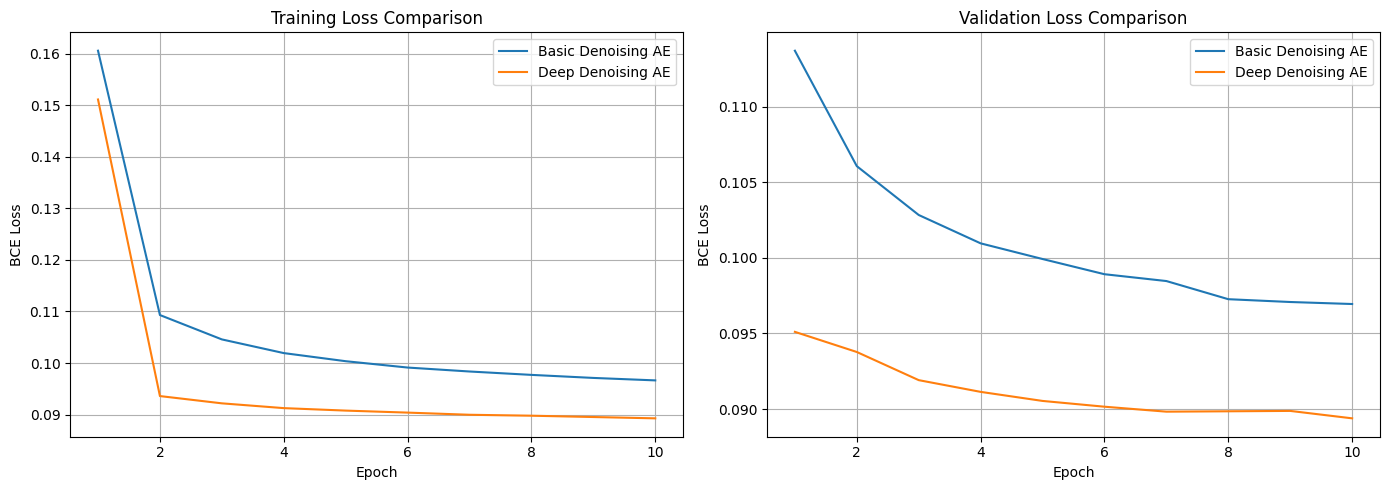

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_basic = range(1, len(history["train_loss"]) + 1)
epochs_deep = range(1, len(deep_history["train_loss"]) + 1)

# Training loss
axes[0].plot(
    epochs_basic,
    history["train_loss"],
    label="Basic Denoising AE"
)

axes[0].plot(
    epochs_deep,
    deep_history["train_loss"],
    label="Deep Denoising AE"
)

axes[0].set_title("Training Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE Loss")
axes[0].legend()
axes[0].grid(True)

# Validation loss
axes[1].plot(
    epochs_basic,
    history["val_loss"],
    label="Basic Denoising AE"
)

axes[1].plot(
    epochs_deep,
    deep_history["val_loss"],
    label="Deep Denoising AE"
)

axes[1].set_title("Validation Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("BCE Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

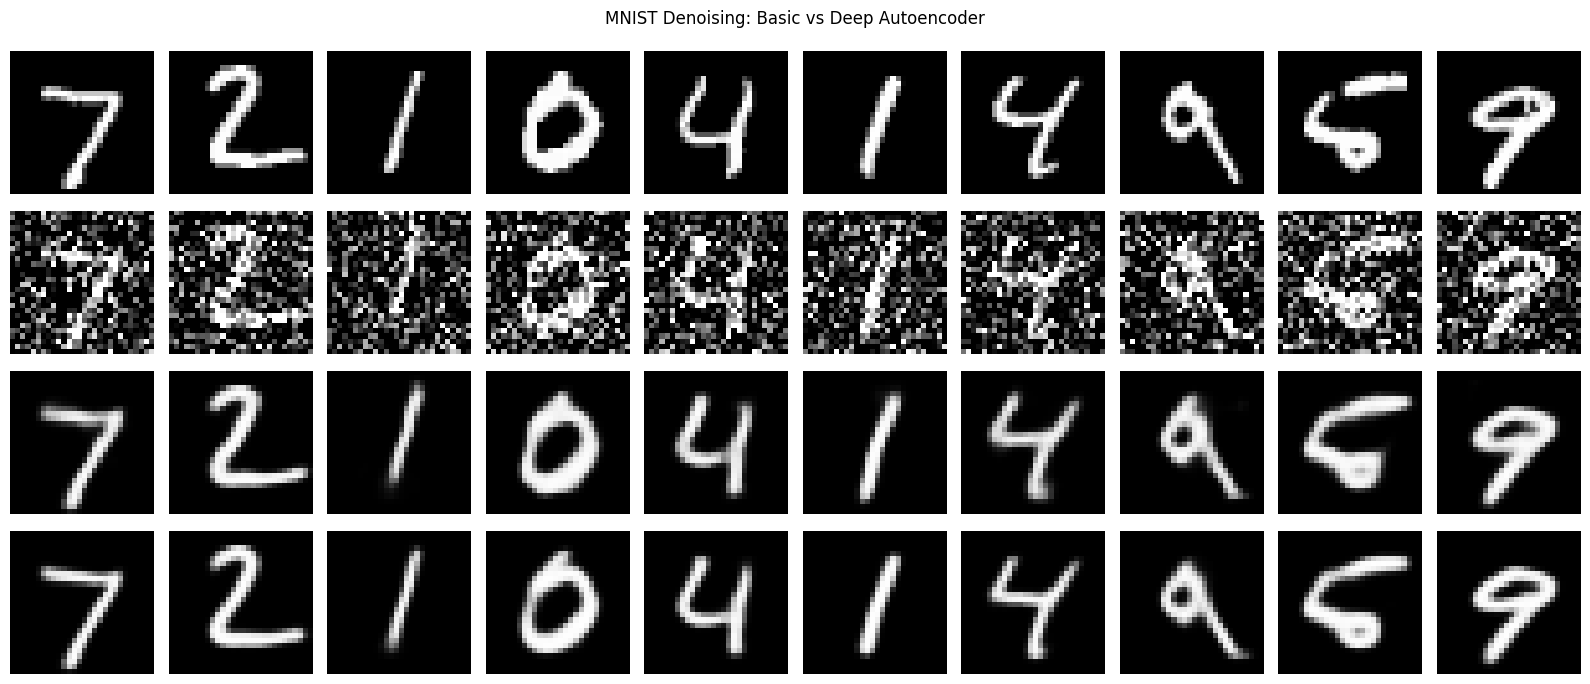

In [19]:
model.eval()
deep_model.eval()

clean_images, labels = next(iter(test_loader))
clean_images = clean_images[:10]

# Generate identical noisy inputs for both models
noise_generator = torch.Generator().manual_seed(5678)

noise = torch.randn(
    clean_images.shape,
    generator=noise_generator
)

noisy_images = torch.clamp(
    clean_images + 0.5 * noise,
    0, 1
)

clean_gpu = clean_images.to(device)
noisy_gpu = noisy_images.to(device)

with torch.no_grad():

    basic_reconstructed = model(noisy_gpu)
    deep_reconstructed = deep_model(noisy_gpu)

clean_np = clean_gpu.cpu().numpy()
noisy_np = noisy_gpu.cpu().numpy()

basic_np = basic_reconstructed.cpu().numpy()
deep_np = deep_reconstructed.cpu().numpy()

fig, axes = plt.subplots(4, 10, figsize=(16, 7))

for i in range(10):

    panels = [
        clean_np[i, 0],
        noisy_np[i, 0],
        basic_np[i, 0],
        deep_np[i, 0]
    ]

    for j in range(4):

        axes[j, i].imshow(
            panels[j],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Clean", fontsize=11)
axes[1, 0].set_ylabel("Noisy", fontsize=11)
axes[2, 0].set_ylabel("Basic AE", fontsize=11)
axes[3, 0].set_ylabel("Deep AE", fontsize=11)

plt.suptitle(
    "MNIST Denoising: Basic vs Deep Autoencoder"
)

plt.tight_layout()
plt.show()

In [20]:
save_dir = "/content/tutorial13_deep_results"

os.makedirs(save_dir, exist_ok=True)

torch.save(
    deep_model.state_dict(),
    f"{save_dir}/deep_denoising_autoencoder.pth"
)

pd.DataFrame(deep_history).to_csv(
    f"{save_dir}/deep_training_history.csv",
    index=False
)

comparison_df.to_csv(
    f"{save_dir}/denoising_model_comparison.csv",
    index=False
)

fig.savefig(
    f"{save_dir}/reconstruction_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

print("Deep autoencoder experiment saved.")

display(comparison_df.round(6))

Deep autoencoder experiment saved.


,Model,Parameters,Test BCE,Test MSE
0,Basic Denoising Autoencoder,74497,0.095913,0.011030
1,Deep Denoising Autoencoder,252609,0.088734,0.008836


## Analysis

Both models successfully learned to reconstruct clean MNIST digits from noisy inputs.

The deep denoising autoencoder achieved lower training and validation reconstruction losses, indicating improved performance under the tested conditions.

The additional convolutional layers increased the model's feature extraction capacity, while Batch Normalization and transposed convolutions modified the learning and reconstruction processes.

Visual inspection showed that both models removed substantial noise. However, the deep autoencoder generally produced cleaner digit boundaries and preserved handwritten strokes more accurately.

The improved performance came with greater computational complexity. The deep model contained 252,609 parameters, compared with 74,497 in the basic architecture.

# Task 2: Implement a Variational Autoencoder (VAE)

In [21]:
class DenoisingVAE(nn.Module):

    def __init__(self, latent_dim=16):
        super().__init__()

        self.latent_dim = latent_dim

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Flatten()
        )

        # Mean and log variance
        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)

        # Decoder
        self.fc_decode = nn.Linear(latent_dim, 64 * 7 * 7)

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                64, 32,
                kernel_size=2,
                stride=2
            ),
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 1,
                kernel_size=2,
                stride=2
            ),
            nn.Sigmoid()
        )

    def encode(self, x):

        h = self.encoder(x)

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

    def reparameterize(self, mu, logvar):

        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)

        z = mu + eps * std

        return z

    def decode(self, z):

        h = self.fc_decode(z)

        h = h.view(-1, 64, 7, 7)

        return self.decoder(h)

    def forward(self, x, use_mean=False):

        mu, logvar = self.encode(x)

        if use_mean:
            z = mu
        else:
            z = self.reparameterize(mu, logvar)

        reconstructed = self.decode(z)

        return reconstructed, mu, logvar


vae_model = DenoisingVAE(latent_dim=16).to(device)

print(vae_model)

DenoisingVAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=3136, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=3136, out_features=16, bias=True)
  (fc_decode): Linear(in_features=16, out_features=3136, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(2, 2), stride=(2, 2))
    (1): ReLU()
    (2): ConvTranspose2d(32, 1, kernel_size=(2, 2), stride=(2, 2))
    (3): Sigmoid()
  )
)


In [22]:
dummy_input = torch.rand(1, 1, 28, 28).to(device)

vae_model.eval()

with torch.no_grad():

    reconstructed, mu, logvar = vae_model(dummy_input)

print("Input:", dummy_input.shape)
print("Mean:", mu.shape)
print("Log Variance:", logvar.shape)
print("Reconstructed:", reconstructed.shape)

vae_params = sum(
    p.numel() for p in vae_model.parameters()
)

print("VAE Parameters:", f"{vae_params:,}")

Input: torch.Size([1, 1, 28, 28])
Mean: torch.Size([1, 16])
Log Variance: torch.Size([1, 16])
Reconstructed: torch.Size([1, 1, 28, 28])
VAE Parameters: 180,865


In [23]:
import torch.nn.functional as F

def vae_loss(reconstructed, target, mu, logvar):

    batch_size = target.size(0)

    # Reconstruction BCE, summed over pixels
    reconstruction_loss = F.binary_cross_entropy(
        reconstructed,
        target,
        reduction="sum"
    ) / batch_size

    # KL divergence, summed over latent dimensions
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    ) / batch_size

    total_loss = reconstruction_loss + kl_loss

    return total_loss, reconstruction_loss, kl_loss

In [24]:
def evaluate_vae(
    model,
    data_loader,
    noise_factor=0.5,
    seed=1234,
    use_mean=False
):

    model.eval()

    generator = torch.Generator().manual_seed(seed)

    total_bce = 0
    total_mse = 0
    total_kl = 0
    total_pixels = 0
    total_images = 0

    with torch.no_grad():

        for clean, _ in data_loader:

            batch_size = clean.size(0)

            # Reproducible noisy inputs
            noise = torch.randn(
                clean.shape,
                generator=generator
            )

            noisy = torch.clamp(
                clean + noise_factor * noise,
                0, 1
            ).to(device)

            clean = clean.to(device)

            mu, logvar = model.encode(noisy)

            if use_mean:
                z = mu
            else:
                eps = torch.randn(
                    mu.shape,
                    generator=generator
                ).to(device)

                z = mu + torch.exp(0.5 * logvar) * eps

            reconstructed = model.decode(z)

            total_bce += F.binary_cross_entropy(
                reconstructed,
                clean,
                reduction="sum"
            ).item()

            total_mse += F.mse_loss(
                reconstructed,
                clean,
                reduction="sum"
            ).item()

            total_kl += (
                -0.5 * torch.sum(
                    1 + logvar - mu.pow(2) - logvar.exp()
                )
            ).item()

            total_pixels += clean.numel()
            total_images += batch_size

    return {
        "BCE": total_bce / total_pixels,
        "MSE": total_mse / total_pixels,
        "KL": total_kl / total_images,
        "Total Loss": (total_bce + total_kl) / total_images
    }


def train_vae(
    model,
    train_loader,
    val_loader,
    epochs=10,
    lr=0.001,
    noise_factor=0.5
):

    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_total": [],
        "train_reconstruction": [],
        "train_kl": [],
        "val_total": [],
        "val_bce": [],
        "val_kl": []
    }

    best_val_loss = float("inf")
    best_weights = None
    best_epoch = 0

    for epoch in range(epochs):

        model.train()

        running_total = 0
        running_recon = 0
        running_kl = 0

        for clean, _ in train_loader:

            clean = clean.to(device)

            noisy = add_noise(
                clean,
                noise_factor
            )

            optimizer.zero_grad()

            reconstructed, mu, logvar = model(noisy)

            total, recon, kl = vae_loss(
                reconstructed,
                clean,
                mu,
                logvar
            )

            total.backward()
            optimizer.step()

            n = clean.size(0)

            running_total += total.item() * n
            running_recon += recon.item() * n
            running_kl += kl.item() * n

        n_train = len(train_loader.dataset)

        train_total = running_total / n_train
        train_recon = running_recon / n_train
        train_kl = running_kl / n_train

        val_metrics = evaluate_vae(
            model,
            val_loader,
            noise_factor=noise_factor,
            seed=1234,
            use_mean=False
        )

        history["train_total"].append(train_total)
        history["train_reconstruction"].append(train_recon)
        history["train_kl"].append(train_kl)

        history["val_total"].append(
            val_metrics["Total Loss"]
        )
        history["val_bce"].append(
            val_metrics["BCE"]
        )
        history["val_kl"].append(
            val_metrics["KL"]
        )

        if val_metrics["Total Loss"] < best_val_loss:

            best_val_loss = val_metrics["Total Loss"]
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Total: {train_total:.3f} | "
            f"Train Recon: {train_recon:.3f} | "
            f"Train KL: {train_kl:.3f} | "
            f"Val Total: {val_metrics['Total Loss']:.3f}"
        )

    model.load_state_dict(best_weights)

    print("\nBest Epoch:", best_epoch)
    print("Best Validation Total Loss:", round(best_val_loss, 4))

    return model, history

In [25]:
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

vae_model = DenoisingVAE(latent_dim=16).to(device)

vae_model, vae_history = train_vae(
    model=vae_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=10,
    lr=0.001,
    noise_factor=NOISE_FACTOR
)

Epoch 01/10 | Train Total: 191.356 | Train Recon: 173.884 | Train KL: 17.471 | Val Total: 145.565
Epoch 02/10 | Train Total: 139.237 | Train Recon: 118.151 | Train KL: 21.086 | Val Total: 135.088
Epoch 03/10 | Train Total: 131.618 | Train Recon: 110.051 | Train KL: 21.567 | Val Total: 129.117
Epoch 04/10 | Train Total: 127.166 | Train Recon: 105.542 | Train KL: 21.624 | Val Total: 126.368
Epoch 05/10 | Train Total: 124.698 | Train Recon: 103.137 | Train KL: 21.561 | Val Total: 123.999
Epoch 06/10 | Train Total: 123.020 | Train Recon: 101.545 | Train KL: 21.475 | Val Total: 122.566
Epoch 07/10 | Train Total: 121.957 | Train Recon: 100.498 | Train KL: 21.459 | Val Total: 121.766
Epoch 08/10 | Train Total: 121.190 | Train Recon: 99.762 | Train KL: 21.428 | Val Total: 120.988
Epoch 09/10 | Train Total: 120.568 | Train Recon: 99.144 | Train KL: 21.424 | Val Total: 120.495
Epoch 10/10 | Train Total: 120.110 | Train Recon: 98.623 | Train KL: 21.487 | Val Total: 120.224

Best Epoch: 10
Best Va

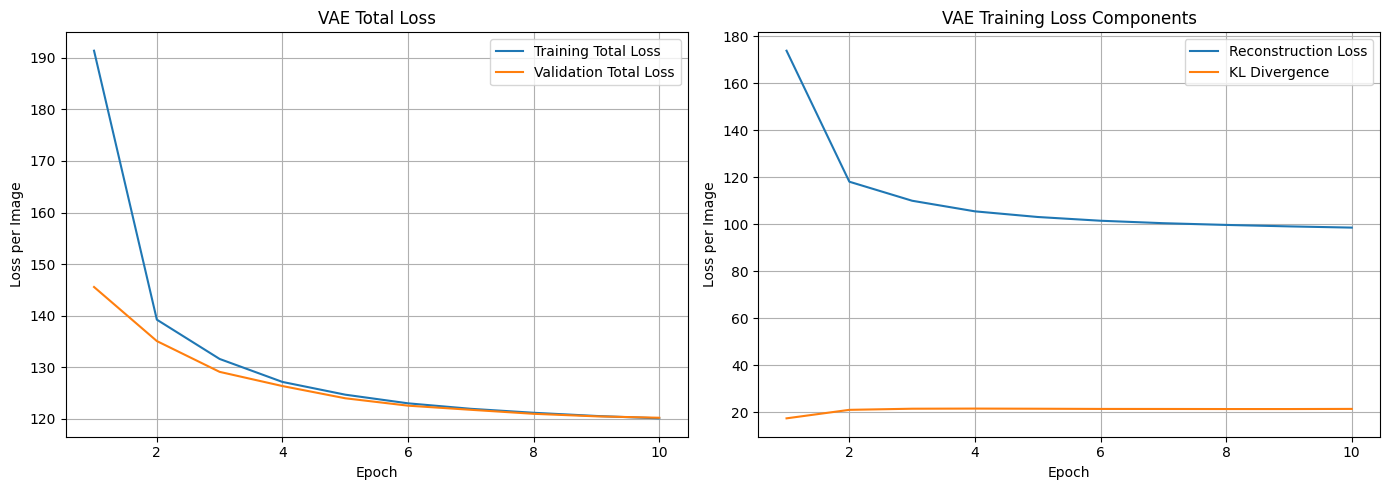

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, len(vae_history["train_total"]) + 1)

axes[0].plot(
    epochs,
    vae_history["train_total"],
    label="Training Total Loss"
)

axes[0].plot(
    epochs,
    vae_history["val_total"],
    label="Validation Total Loss"
)

axes[0].set_title("VAE Total Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss per Image")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    epochs,
    vae_history["train_reconstruction"],
    label="Reconstruction Loss"
)

axes[1].plot(
    epochs,
    vae_history["train_kl"],
    label="KL Divergence"
)

axes[1].set_title("VAE Training Loss Components")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss per Image")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [27]:
# Sampled-latent evaluation of the VAE objective
vae_sampled_metrics = evaluate_vae(
    vae_model,
    test_loader,
    noise_factor=NOISE_FACTOR,
    seed=5678,
    use_mean=False
)

# Deterministic reconstruction using the latent mean
vae_metrics = evaluate_vae(
    vae_model,
    test_loader,
    noise_factor=NOISE_FACTOR,
    seed=5678,
    use_mean=True
)

print("VAE TEST RESULTS")
print("-" * 40)

print(
    f"Sampled VAE Total Loss: "
    f"{vae_sampled_metrics['Total Loss']:.4f}"
)

print(
    f"KL Divergence per Image: "
    f"{vae_sampled_metrics['KL']:.4f}"
)

print(
    f"Deterministic Test BCE: "
    f"{vae_metrics['BCE']:.6f}"
)

print(
    f"Deterministic Test MSE: "
    f"{vae_metrics['MSE']:.6f}"
)

VAE TEST RESULTS
----------------------------------------
Sampled VAE Total Loss: 119.0519
KL Divergence per Image: 22.1540
Deterministic Test BCE: 0.115052
Deterministic Test MSE: 0.017190


In [28]:
basic_metrics = evaluate_denoising(
    model,
    test_loader,
    noise_factor=NOISE_FACTOR,
    seed=5678
)

deep_metrics = evaluate_denoising(
    deep_model,
    test_loader,
    noise_factor=NOISE_FACTOR,
    seed=5678
)

comparison_all = pd.DataFrame({
    "Model": [
        "Basic Denoising AE",
        "Deep Denoising AE",
        "Variational AE"
    ],

    "Parameters": [
        basic_params,
        deep_params,
        sum(p.numel() for p in vae_model.parameters())
    ],

    "Test BCE": [
        basic_metrics["BCE"],
        deep_metrics["BCE"],
        vae_metrics["BCE"]
    ],

    "Test MSE": [
        basic_metrics["MSE"],
        deep_metrics["MSE"],
        vae_metrics["MSE"]
    ]
})

display(comparison_all.round(6))

best_model = comparison_all.loc[
    comparison_all["Test MSE"].idxmin(),
    "Model"
]

print("Lowest test MSE:", best_model)

,Model,Parameters,Test BCE,Test MSE
0,Basic Denoising AE,74497,0.095913,0.011030
1,Deep Denoising AE,252609,0.088734,0.008836
2,Variational AE,180865,0.115052,0.017190


Lowest test MSE: Deep Denoising AE


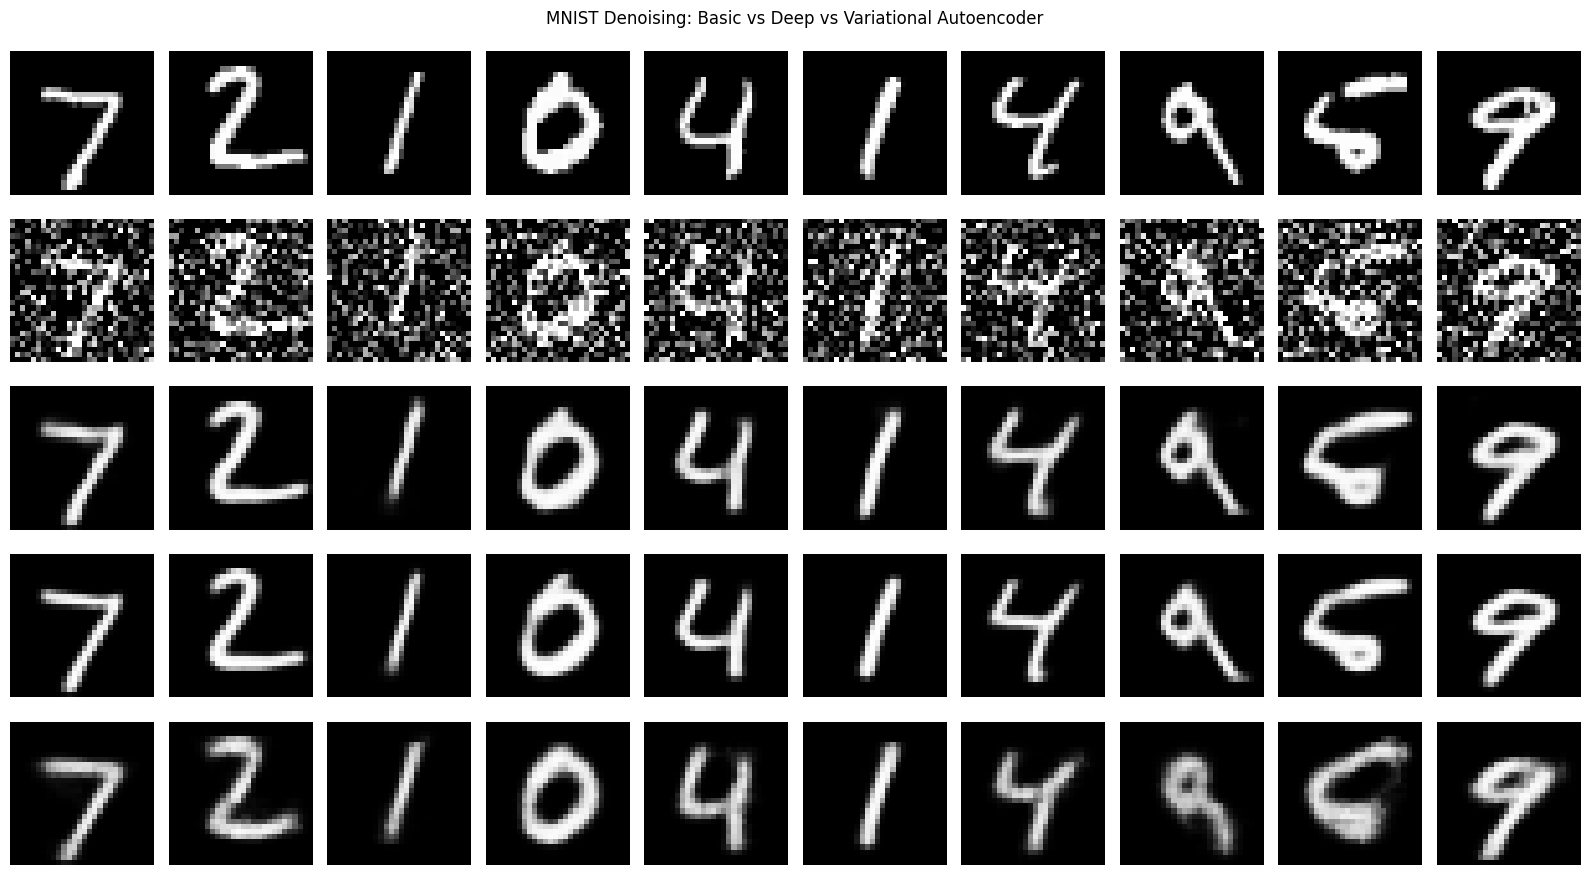

In [29]:
model.eval()
deep_model.eval()
vae_model.eval()

clean_images, labels = next(iter(test_loader))
clean_images = clean_images[:10]

generator = torch.Generator().manual_seed(5678)

noise = torch.randn(
    clean_images.shape,
    generator=generator
)

noisy_images = torch.clamp(
    clean_images + NOISE_FACTOR * noise,
    0, 1
)

clean_gpu = clean_images.to(device)
noisy_gpu = noisy_images.to(device)

with torch.no_grad():

    basic_recon = model(noisy_gpu)

    deep_recon = deep_model(noisy_gpu)

    # Deterministic reconstruction
    vae_recon, _, _ = vae_model(
        noisy_gpu,
        use_mean=True
    )

panels = [
    clean_gpu.cpu().numpy(),
    noisy_gpu.cpu().numpy(),
    basic_recon.cpu().numpy(),
    deep_recon.cpu().numpy(),
    vae_recon.cpu().numpy()
]

names = [
    "Clean",
    "Noisy",
    "Basic AE",
    "Deep AE",
    "VAE"
]

fig, axes = plt.subplots(5, 10, figsize=(16, 9))

for row in range(5):

    for col in range(10):

        axes[row, col].imshow(
            panels[row][col, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(
        names[row],
        fontsize=11
    )

plt.suptitle(
    "MNIST Denoising: Basic vs Deep vs Variational Autoencoder"
)

plt.tight_layout()
plt.show()

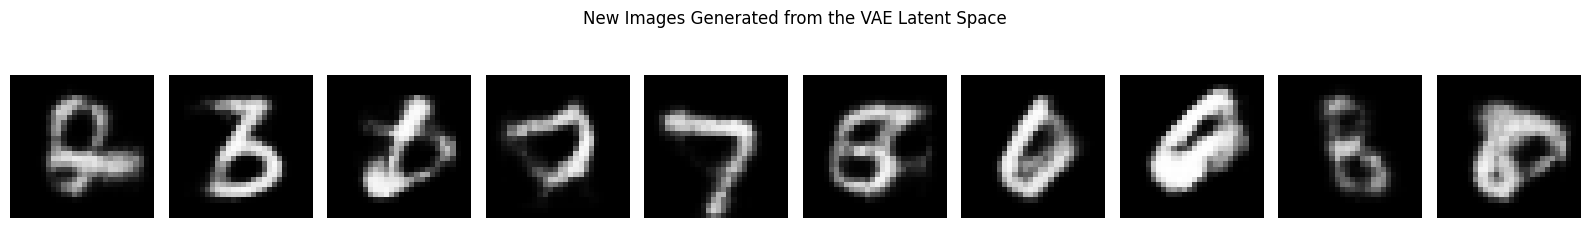

In [30]:
vae_model.eval()

with torch.no_grad():

    # Sample random latent vectors
    z = torch.randn(
        10,
        vae_model.latent_dim,
        device=device
    )

    generated = vae_model.decode(z).cpu().numpy()

fig, axes = plt.subplots(1, 10, figsize=(16, 2.5))

for i in range(10):

    axes[i].imshow(
        generated[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].axis("off")

plt.suptitle("New Images Generated from the VAE Latent Space")
plt.tight_layout()
plt.show()

In [31]:
save_dir = "/content/tutorial13_vae_results"

os.makedirs(save_dir, exist_ok=True)

torch.save(
    vae_model.state_dict(),
    f"{save_dir}/denoising_vae.pth"
)

pd.DataFrame(vae_history).to_csv(
    f"{save_dir}/vae_training_history.csv",
    index=False
)

comparison_all.to_csv(
    f"{save_dir}/all_autoencoders_comparison.csv",
    index=False
)

vae_results = pd.DataFrame([{
    "Latent Dimensions": 16,
    "Epochs": 10,
    "Test BCE": vae_metrics["BCE"],
    "Test MSE": vae_metrics["MSE"],
    "Sampled Test Total Loss": vae_sampled_metrics["Total Loss"],
    "Test KL per Image": vae_sampled_metrics["KL"]
}])

vae_results.to_csv(
    f"{save_dir}/vae_test_results.csv",
    index=False
)

display(vae_results)
display(comparison_all.round(6))

print("VAE model and experiment results saved.")

,Latent Dimensions,Epochs,Test BCE,Test MSE,Sampled Test Total Loss,Test KL per Image
0,16,10,0.115052,0.01719,119.051896,22.153971


,Model,Parameters,Test BCE,Test MSE
0,Basic Denoising AE,74497,0.095913,0.011030
1,Deep Denoising AE,252609,0.088734,0.008836
2,Variational AE,180865,0.115052,0.017190


VAE model and experiment results saved.


## Analysis

The VAE successfully learned a probabilistic latent representation of noisy MNIST images. Its training and validation total losses decreased over the 10 epochs, indicating successful optimization.

However, the VAE achieved higher reconstruction BCE and MSE than the basic and deep denoising autoencoders.

The deep denoising autoencoder achieved the lowest test BCE of 0.088734 and test MSE of 0.008836, making it the strongest reconstruction model among the three architectures under the tested conditions.

Visual inspection showed that the VAE reconstructed recognizable handwritten digits, although its outputs generally contained smoother and blurrier strokes than those produced by the conventional autoencoders.

Unlike conventional autoencoders, the VAE also supported the generation of new images. Random samples from its latent space produced several recognizable digit-like patterns, although some generated samples were ambiguous.

The higher reconstruction error does not necessarily indicate an unsuccessful VAE because its training objective includes KL-divergence regularization in addition to reconstruction accuracy. Its compact 16-dimensional latent representation also differs substantially from the larger spatial representations of the other models.